## **Histograms & Distribution Analysis**

### **What is a Histogram?**

A **histogram** Shows how numerical observations are distributed across ranges of values.

Suppose we have 20 customer order values:

```text
₹120, ₹150, ₹180, ₹220, ₹240, ₹270,
₹310, ₹320, ₹350, ₹380, ₹420, ₹450,
₹470, ₹500, ₹520, ₹550, ₹600, ₹620,
₹700, ₹850
```

Instead of looking at every number individually, we can group them:

```text
₹100–200   → 3 customers
₹200–300   → 3 customers
₹300–400   → 4 customers
₹400–500   → 4 customers
₹500–600   → 3 customers
₹600–700   → 2 customers
₹700–800   → 0 customers
₹800–900   → 1 customer
```
A histogram visualizes this distribution.

### **Why does a histogram exists?**

we have in an e-commerce dataset:
```text
5 million order values
```

The averave order value is:
```text
1,250
```
Sounds useful. But there's a problem, Maybe the actual data looks like:
```text
Most customers → ₹200–₹500
Few customers  → ₹1,000–₹3,000
Very few       → ₹50,000+
```

The average of 1,250 hides this structure.

A histogram lets us see:

> Where are most observations concentrated?

> How spread out is the data?

> Is the distribution symmetric or skewed?

> Are there unusual observations?

This is why histograms are extremely important in EDA.

### **Our first histogram**

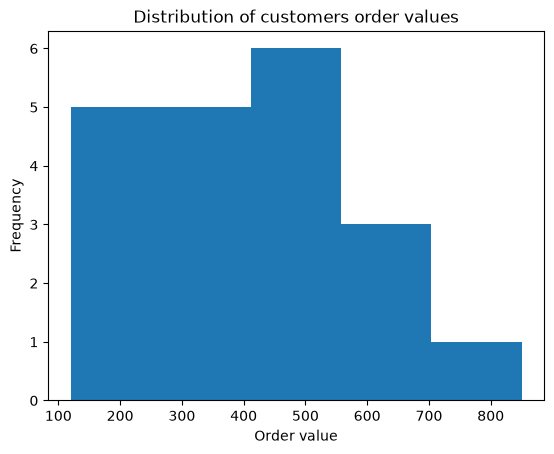

In [8]:
import matplotlib.pyplot as plt

order_values = [
    120, 150, 180, 220, 240, 270,
    310, 320, 350, 380, 420, 450,
    470, 500, 520, 550, 600, 620,
    700, 850
]

fig, ax = plt.subplots()

ax.hist(
    order_values,
    bins = 5,
    # density= True
)

ax.set_title('Distribution of customers order values')
ax.set_xlabel('Order value')
ax.set_ylabel('Frequency')

plt.show()

That's our first histogram.

### **What is frequency means?**

number observations does each distribution have.

### **Bins: The most important concept**

A histogram doesn't show every individual vlaue. It groups values into **bins**.

Suppose:
```text
Order values:

100
150
180
230
250
310
350
420
480
520
```

We could create bins:

```text
100–200
200–300
300–400
400–500
500–600
```
Conceptually:
```text
Bin 1 → 100–200
Bin 2 → 200–300
Bin 3 → 300–400
Bin 4 → 400–500
Bin 5 → 500–600
```

Each bar tells us how many observations fall inside its range.

### **controlling bins**

In Matplotlib:
```python
ax.hist(order_values, bins=5)
```
means:
> Divide the data into 5 bins.

### **why does the number of bins matter?**

> Bin selection affects what patterns we can see.

Imagine the actual distribution is:

```text
     ███████
   ███████████
 ███████████████
   ███████████
     ███████
```

But if we choose too few bins:
```text
       █████
       █████
       █████
```
it'll look like this, choosing too many bins:
```text
█ █ ██ █ █ █ █ ██ █ █ █
```
Now the graph becomes noisy.

And this is why we shouldn't blindly choose bins for every dataset.

### **Understanding Distribution Shape**

Now comes the real analyst skill.

When we look at the histogram, we don't just say:
> "There are bars."

Ask:
> "What shape does the data have?"

Several Patterns are important.

#### **1.Symmetric Distribution**

In this distribution the histogram shape would be:
- The left and right sides are roughly similar.

We can say then the histogram is approximately **symmetric**.

A famous example is the normal distribution:
```text
                    ●
                 ●     ●
              ●           ●
           ●                 ●
        ●                       ●
──────●───────────────────────────●──────
```
The center contains the most distribution.

#### **2. Right-Skewed Distribution**

This is very important in business data.

Imagine customer income:
```text
██████████████
████████████
████████
████
██
█
█
```
Most people falls at lower/middle values, while a small number have extemely high values.

- The long tail extends toward the **right**.

> Right-skewed = Positively skewed

**Real world examples**

Common candidates for _Right-skewed_ distributions:

- Income
- wealth
- transaction values
- house prices
- Customer spending
- company revenue

#### **3. Left-Skewed Distribution**

Opposite situation:
```text
              █████████████
                 █████████
                    █████
                       ██
                        █
                        █
```
The long tail extend towards the **left**.

Therefore:
> Left-skewed = Negatively skewed

Possible example:
- Exam score
- Age of retirement
- Deaht as respect to Age.


### **Why does skewness matter?**

Because it affects how we understand summary statistics.

Consider:
```text
Customer spending

₹100
₹120
₹150
₹180
₹200
₹250
₹300
₹5,000
```
The 5,000rs observation pulls the average upward. So:
```text
Mean ↑
```
While the typical customer may still spend only a few hundred rupees.

That's why analysts often compare:
```text
Mean
Meadian
Distribution
```
Rather than blindly using the mean.

### **Mean vs Median in a righ-skewed distribution**
A common pattern is:
```text
Mean > Median
```
Why? Because extremely large observations pull the mean toward the right tail.

The medain is more resistant to extreme observations.

### **Outliers**

A histogram can sometimes reveal unusual observations. We might see a long tail, those observations deserve investigations.

But here's a crucial point:
> An unusual observation is not automatically an error.

Maybe 100,000 was a legitimate corporate order.

So don't immediately delete it.

Ask:
```text
Is it valid?
     |
Yes -> understand it
No -> investigate data quality
```

### **Histogram doesn't tell you why**

Suppose you see:

```text
Huge spike around Rs 500.
```
we can say:
> Most orders are around this range.

But we cannot automatically say:
> Customers prefer Rs 500 products because of discount strategy.

That would require additional evidence.

Again:

**Visualization shows patterns; analysis investigates explanations.**

### ** Five things to ask when seeing a histogram**

Whenever we see a distribution, ask:

**1. Where is the center?**

Where are most observation concentrated?

**2. How spread out it is?**

Are values tightly packed or widely dispersed?

**3. What is the shape?**

is it:
- symmetric?
- right-skewed?
- left-skewed?
- mulimodal?

**4. Are there unusual observations?**

Look for:
- isolated regions
- long tails
- extreme values

**5. Are there multiple peaks?**

This is especially interesting.

### **Multimodal distributions**

Suppose our histogram looks like:
```text
         ███
       █████
     ███████
         ███
         ███
       █████
     ███████
         ███
```

There are two major peaks.

That's called a:
> Bimodal distribution

Why could this happen?

Maybe our customers consist of two different populations:

```text
Population A
Budget customers

Population B
Premium customers
```
This is where visualization becomes genuinely useful for business analysis.

A single average might hide this completely.


### **Practical Exercise**

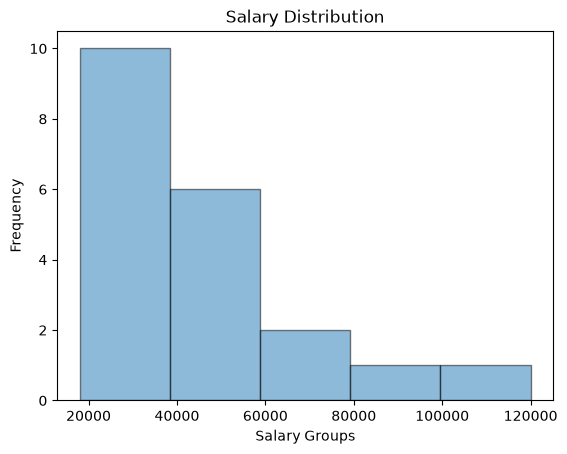

In [9]:
salaries: list = [
    18000, 20000, 22000, 25000, 27000,
    28000, 30000, 32000, 35000, 38000,
    40000, 42000, 45000, 48000, 50000,
    55000, 60000, 65000, 80000, 120000
]

fig, ax = plt.subplots()

ax.hist(
    salaries,
    bins= 5, 
    alpha=0.5,
    edgecolor='black'
)

ax.set_title('Salary Distribution')
ax.set_xlabel('Salary Groups')
ax.set_ylabel('Frequency')

plt.show()

### **Analyst Test**

Don't just code. Answer these.

Answer the following:

1. **What does a histogram represents?**
    - Answer: A histogram represents numerical values distribution across various ranges of values.

2. **What's the difference between a histogram and bar chart?**
    - Answer: A histogram shows the distribution of numerical data across multiple ranges / groups of values, e.g: how many employee's salaries lies between 20k - 40k, 40k - 80k , 80k - 100k. it'll give us the frequency/counts of the employies lies between each range of salary.<br><br>
    Whereas, The bar chart represents a comparison between variuos categories, best use on categorical variables.
    e.g.: Which region generates the more revenues, here regions are the categorical variable and the numerical value is revenues, we compare each region to each other to find out which produces the most revenue.

3. **What is a bin?**
    - Answer: A bin represents the ranges of values/ groups of values where the numerical variable lies on. such as 100k - 200k , 200k - 300k.

4. **What happens if you use too few bins?**
    - Answer: The ranges of distribution becomes too large, which leads to difficulty on analysing the skewness of data, How they are spread.

5. **What happens if you use too many bins?**
    - Answer: The ranges of distribution becomes too small, Now every values seems same, the hist becomes too noisy.

6. **What does right-skewed mean?**
    - Answer: The right skewed means that most of our observations lies on the lower range, visualization would look like a long tail towards right. e.g., Income of Customers, most of them lies on minimum range(20k - 40k) and very few would lies on the higher range (100k - 200k). some others are, wealth, transactions values, Customer order values.

7. **Why can income and customer spending often be right-skewed?**
    - Answer: Most of the population in both cases lies on the lower ranges, and very few of them lies on higher ranges, such most of the customer income would be in (20k - 40k) and few would be in (100k - 200k) same goes for customer spending, lot's them would spend few amounts and few them would be able to spend higher amounts.

8. **Why can the mean be misleading in a highly skewed dataset?**
    - Answer: Mean would be highley affected by the large observations, and highly skewed data might have long gap in distributions. if I give an example: observation [50, 58, 62, 70, 80, 120, 200] , would drastically grasp the mean towards the higher value even though most of the observation are betwee, 50-80.

9. **If a histogram has two peaks, what might that suggest?**
    - Answer: That particular situation is called bimodal distribution, it's suggest that we have two groups of observations in terms of population, e.g., we have a group of midium income consumer and might be premium consumer.

10. **If you find an extreme value, should you automatically delete it?**
    - Answer: I don't think so, extreme value doesn't always means it's an error. It might be possible value, we have to investigate the reason behind it, let's take an example: employees salaries- most of them might fall in the range of 50k - 100k, however If we see a salary of 500k that doesn't mean it's an outlier , it might be of CEOs salry. 